In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("/Users/lucielopez/Desktop/stuff/IRONHACK/LABS/W5/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [ ]:
# PART 1: Analyzing Best-Seller Trends Across Product Categories
# 1

crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab.head())


isBestSeller                   False  True 
category                                   
3D Printers                      247      1
3D Printing & Scanning          4065      2
Abrasive & Finishing Products    245      5
Action Cameras                  1696      1
Adapters                         251      3


In [ ]:
# 2

from scipy.stats import chi2_contingency

# Table de contingence (catégorie × best-seller)
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

# Test du Chi²
chi2, p, dof, expected = chi2_contingency(crosstab)

print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")


Chi2 statistic: 36540.20
Degrees of freedom: 295
P-value: 0.0000


In [ ]:
import numpy as np

# Cramér's V
n = crosstab.sum().sum()   # nombre total d'observations
k = min(crosstab.shape)    # plus petite dimension (nb de lignes ou colonnes)

cramers_v = np.sqrt(chi2 / (n * (k - 1)))

print(f"Cramér's V: {cramers_v:.3f}")

Cramér's V: 0.122


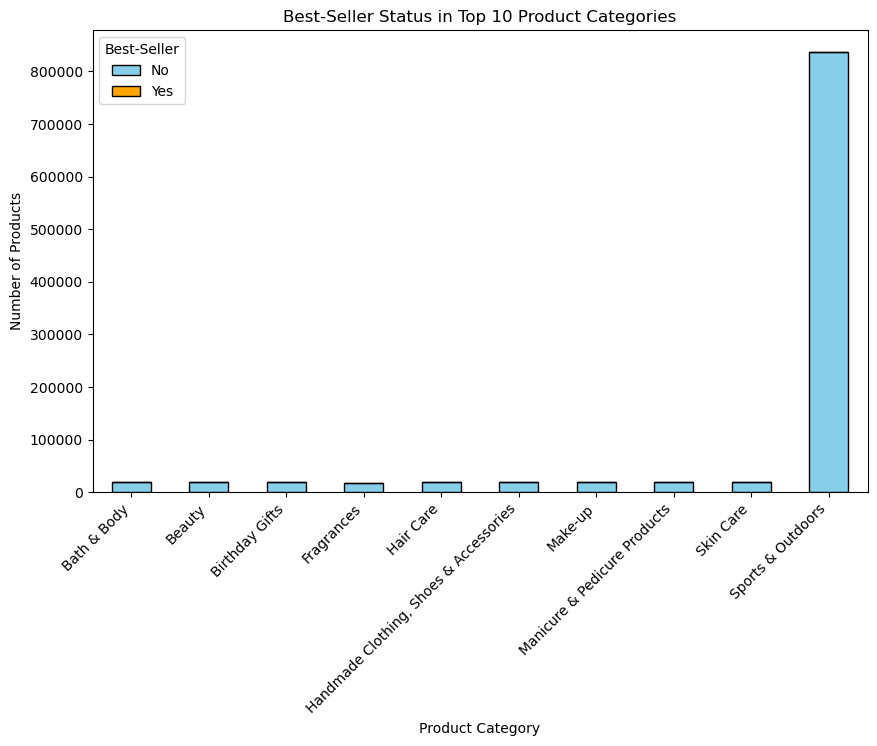

In [12]:
# 3

import matplotlib.pyplot as plt

# Limiter aux top 10 catégories en nombre total de produits
top_categories = df['category'].value_counts().head(10).index
filtered = df[df['category'].isin(top_categories)]

crosstab = pd.crosstab(filtered['category'], filtered['isBestSeller'])

crosstab.plot(kind="bar", stacked=True, figsize=(10,6), color=["skyblue","orange"], edgecolor="black")
plt.title("Best-Seller Status in Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Best-Seller", labels=["No", "Yes"])
plt.show()

In [13]:
# PART 2: Exploring Product Prices and Ratings Across Categories and Brands
# 0

# Supposons que la colonne des prix est 'price'
prices = df['price']

# Quartiles
Q1 = prices.quantile(0.25)
Q3 = prices.quantile(0.75)
IQR = Q3 - Q1

# Bornes
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

# Supprimer les outliers
df_no_outliers = df[(prices >= lower_bound) & (prices <= upper_bound)]

print(f"Original dataset size: {len(df)}")
print(f"Dataset without outliers: {len(df_no_outliers)}")



Q1: 9.99, Q3: 45.99, IQR: 36.0
Lower Bound: -44.01, Upper Bound: 99.99000000000001
Original dataset size: 2443651
Dataset without outliers: 2115963


/var/folders/zv/n5tftmvs15g6v9bt94cd5v400000gn/T/ipykernel_6721/328481147.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=filtered, x="category", y="price", inner="quartile", scale="width", palette="Set2")
/var/folders/zv/n5tftmvs15g6v9bt94cd5v400000gn/T/ipykernel_6721/328481147.py:10: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=filtered, x="category", y="price", inner="quartile", scale="width", palette="Set2")


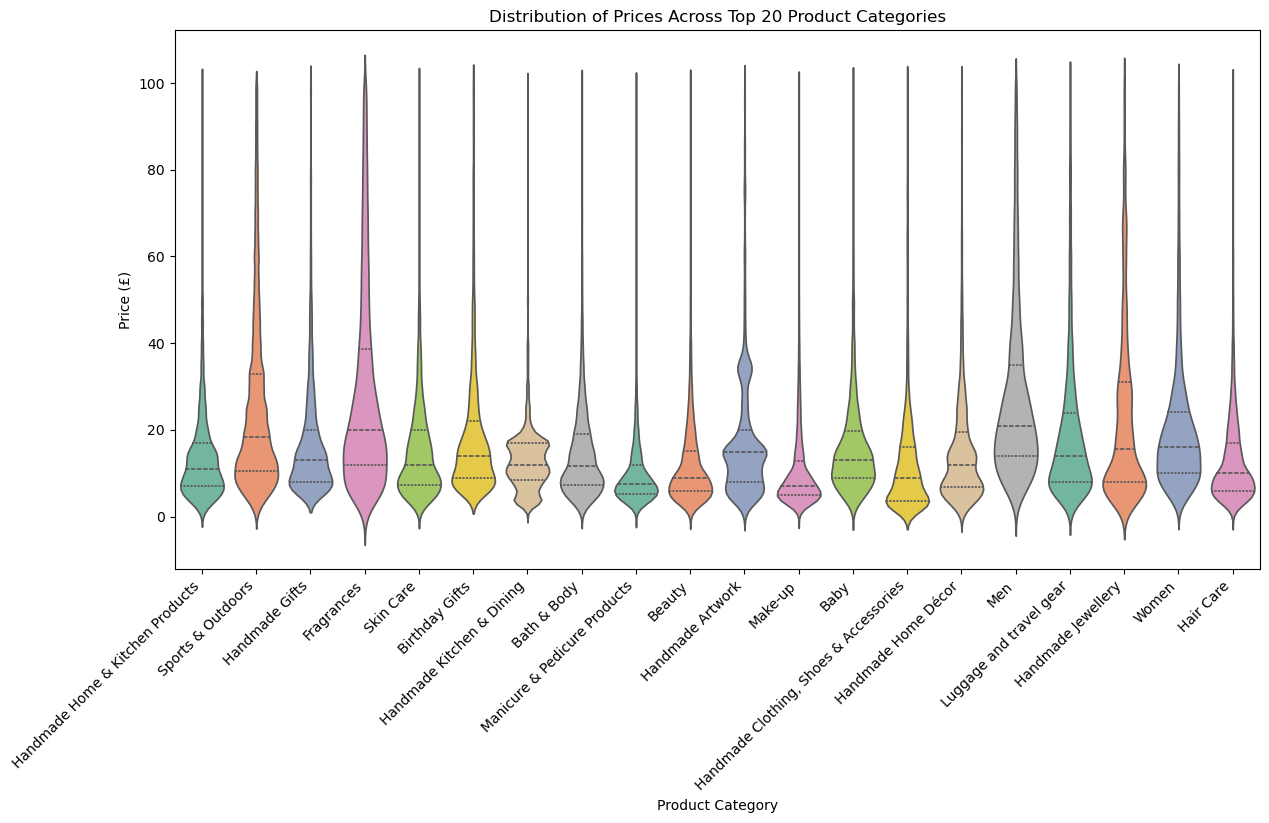

In [15]:
# 1

import seaborn as sns

# 20 categories with most products
top20_categories = df_no_outliers['category'].value_counts().head(20).index
filtered = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

plt.figure(figsize=(14,7))
sns.violinplot(data=filtered, x="category", y="price", inner="quartile", scale="width", palette="Set2")
plt.title("Distribution of Prices Across Top 20 Product Categories")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Price (£)")
plt.xlabel("Product Category")
plt.show()

In [ ]:
# Median by category / outliers
median_prices = df_no_outliers.groupby("category")['price'].median().sort_values(ascending=False)

print("Top categories by median price:")
print(median_prices.head(10))

Top categories by median price:
category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


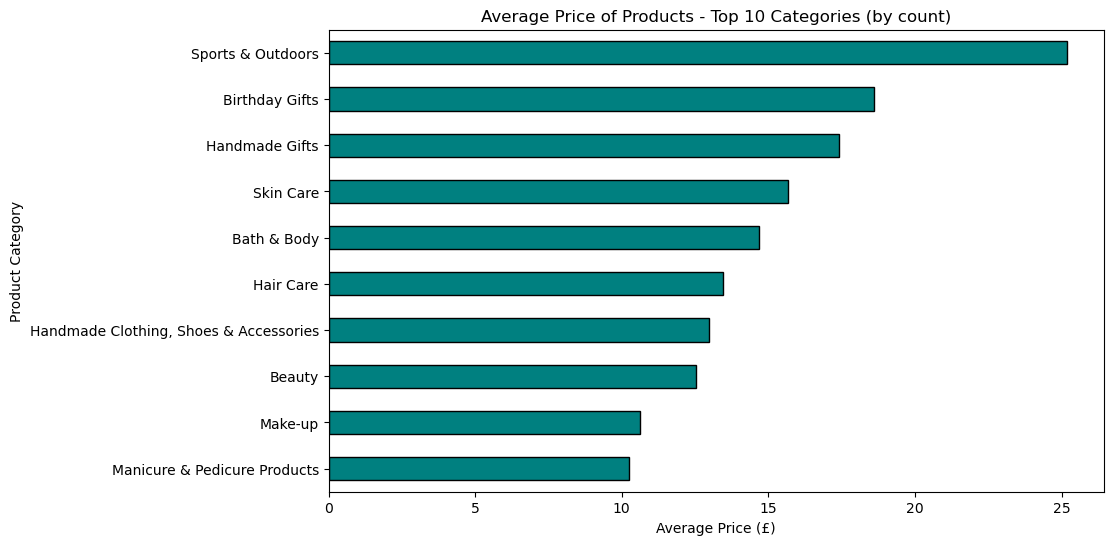

In [17]:
# 2 

# Calculer le prix moyen par catégorie
avg_price = df_no_outliers.groupby("category")['price'].mean().sort_values(ascending=False)

# Sélectionner les top 10 catégories par nombre de produits
top10_categories = df_no_outliers['category'].value_counts().head(10).index
avg_price_top10 = avg_price[avg_price.index.isin(top10_categories)]

# Plot
plt.figure(figsize=(10,6))
avg_price_top10.sort_values().plot(kind="barh", color="teal", edgecolor="black")

plt.title("Average Price of Products - Top 10 Categories (by count)")
plt.xlabel("Average Price (£)")
plt.ylabel("Product Category")
plt.show()

In [18]:
highest_avg_price = avg_price.head(1)
print("Category with the highest average price:")
print(highest_avg_price)

Category with the highest average price:
category
Motherboards    68.772432
Name: price, dtype: float64


/var/folders/zv/n5tftmvs15g6v9bt94cd5v400000gn/T/ipykernel_6721/3913095116.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered, x='category', y='stars', palette="Pastel1")


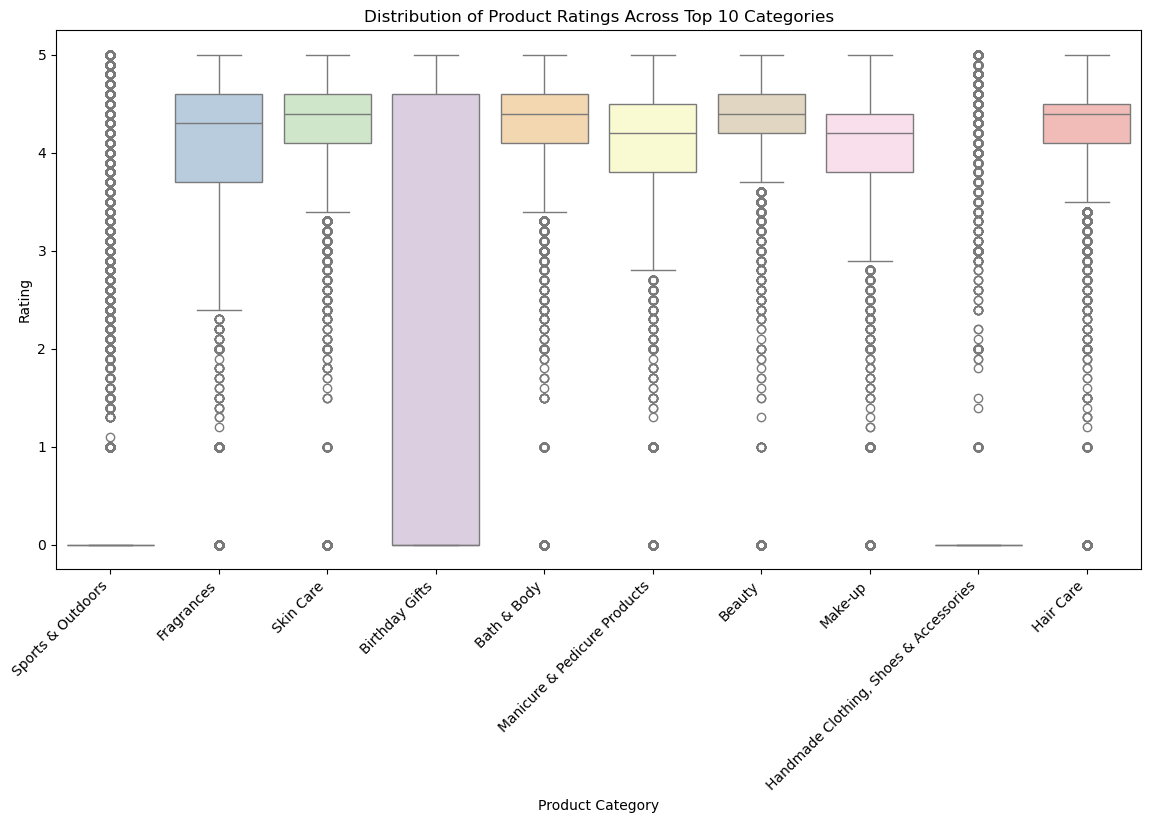

In [21]:
# 3

# Top 10 catégories par nombre de produits
top10_categories = df['category'].value_counts().head(10).index
filtered = df[df['category'].isin(top10_categories)]

plt.figure(figsize=(14,7))
sns.boxplot(data=filtered, x='category', y='stars', palette="Pastel1")
plt.title("Distribution of Product Ratings Across Top 10 Categories")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Product Category")
plt.ylabel("Rating")
plt.show()


In [23]:
median_ratings = df.groupby("category")['stars'].median().sort_values(ascending=False)

print("Top categories by median rating:")
print(median_ratings.head(10))

Top categories by median rating:
category
Computer Memory                 4.7
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Kids' Play Figures              4.6
Building & Construction Toys    4.6
CPUs                            4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Camera & Photo Accessories      4.5
Name: stars, dtype: float64


In [25]:
# PART 3: Investigating the Interplay Between Product Prices and Ratings
# 1

correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print(f"Correlation coefficient between price and rating: {correlation:.3f}")

Correlation coefficient between price and rating: -0.078


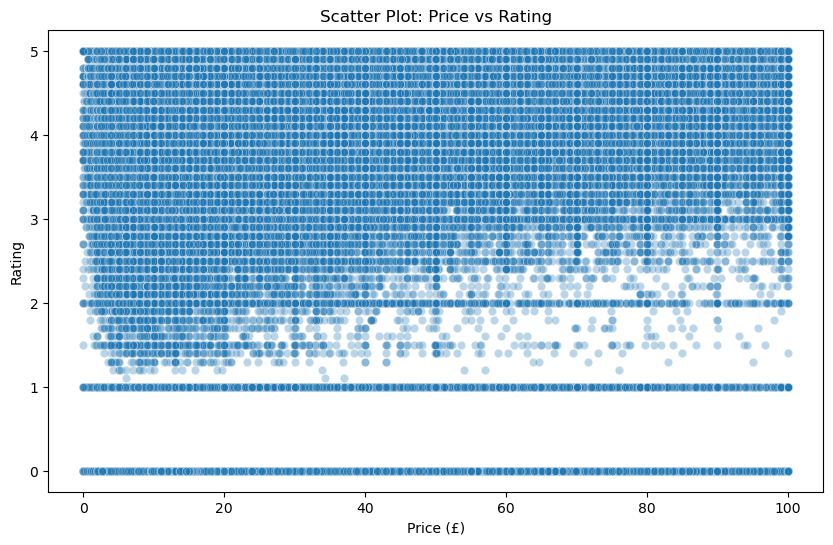

In [27]:
# 2

plt.figure(figsize=(10,6))
sns.scatterplot(data=df_no_outliers, x='price', y='stars', alpha=0.3)
plt.title("Scatter Plot: Price vs Rating")
plt.xlabel("Price (£)")
plt.ylabel("Rating")
plt.show()

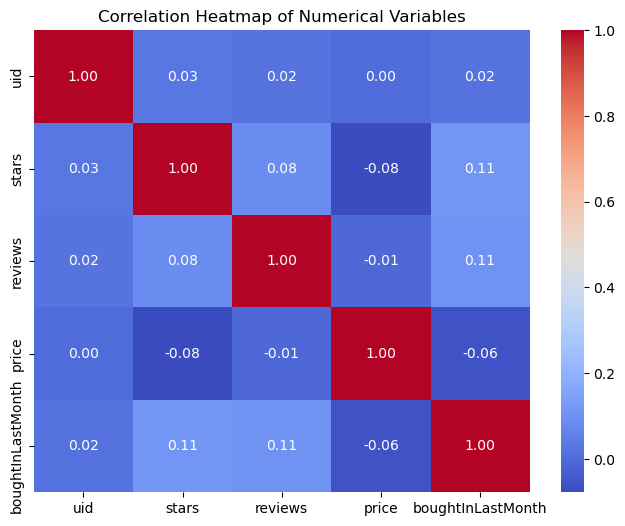

In [28]:
plt.figure(figsize=(8,6))
numeric_cols = df_no_outliers.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df_no_outliers[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

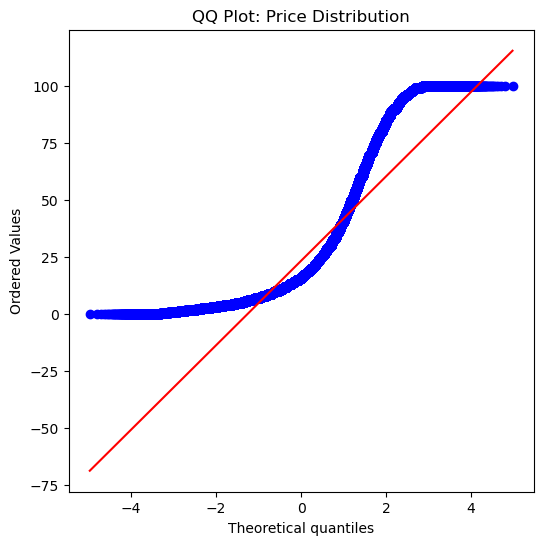

In [30]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot: Price Distribution")
plt.show()